In [11]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")

csv_candidates = [
    Path("Dataset/Sample - Superstore.csv"),
    Path("../Dataset/Sample - Superstore.csv"),
    Path("Sample - Superstore.csv"),
    Path("../Sample - Superstore.csv"),
    Path("Dataset/Superstore.csv"),
    Path("../Dataset/Superstore.csv"),
    Path("Superstore.csv"),
    Path("../Superstore.csv"),
]
csv_path = next((path for path in csv_candidates if path.exists()), None)
if csv_path is None:
    raise FileNotFoundError("Could not find Sample - Superstore.csv or Superstore.csv in the workspace or Dataset folder.")

df = pd.read_csv(csv_path, encoding="cp1252")
df.columns = df.columns.str.strip()
print(df.columns.tolist())
print(df.shape)
df.head()

['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']
(9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [12]:
print("DataFrame info:")
df.info()

print("\nMissing values per column:")
display(df.isnull().sum())

print(f"\nDuplicate rows: {df.duplicated().sum()}")

print("\nDescriptive statistics:")
display(df.describe())

DataFrame info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


Duplicate rows: 0

Descriptive statistics:


,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


Total sales by category:


,Category,Sales
2,Technology,836154.0330
0,Furniture,741999.7953
1,Office Supplies,719047.0320


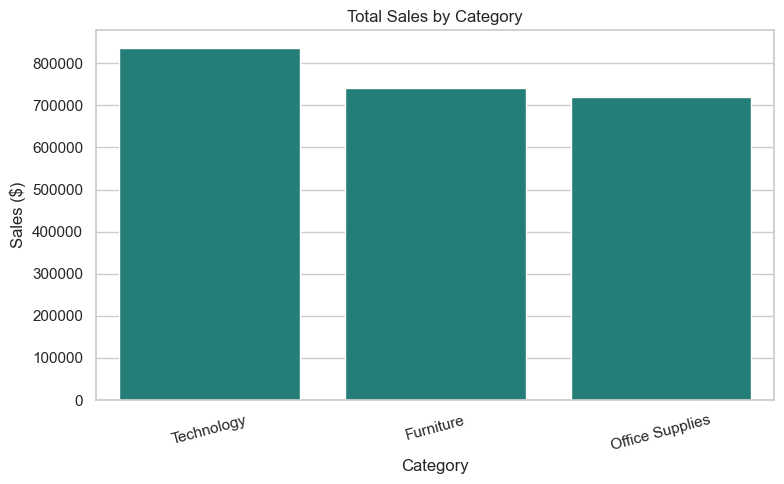

Total sales by region:


,Region,Sales
3,West,725457.8245
1,East,678781.2400
0,Central,501239.8908
2,South,391721.9050


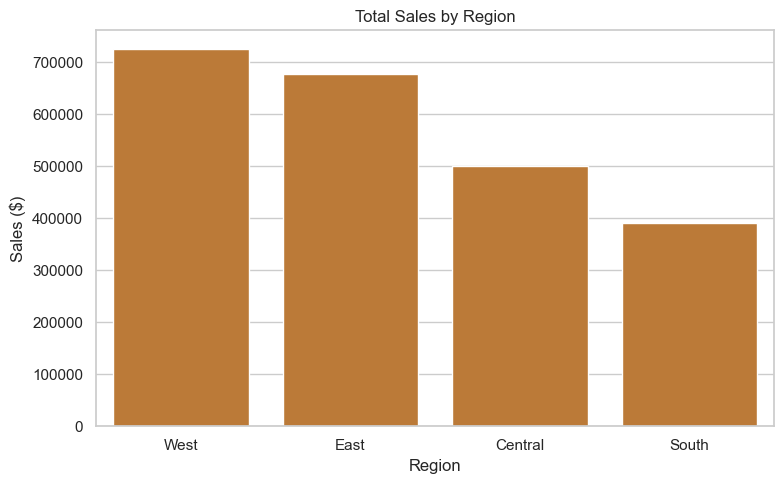

In [13]:
category_sales = (
    df.groupby("Category", as_index=False)["Sales"]
    .sum()
    .sort_values("Sales", ascending=False)
)
region_sales = (
    df.groupby("Region", as_index=False)["Sales"]
    .sum()
    .sort_values("Sales", ascending=False)
)

print("Total sales by category:")
display(category_sales)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=category_sales, x="Category", y="Sales", color="#168C83", ax=ax)
ax.set(title="Total Sales by Category", xlabel="Category", ylabel="Sales ($)")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

print("Total sales by region:")
display(region_sales)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=region_sales, x="Region", y="Sales", color="#D17A22", ax=ax)
ax.set(title="Total Sales by Region", xlabel="Region", ylabel="Sales ($)")
plt.tight_layout()
plt.show()

Total profit by category:


,Category,Profit
2,Technology,145454.9481
1,Office Supplies,122490.8008
0,Furniture,18451.2728


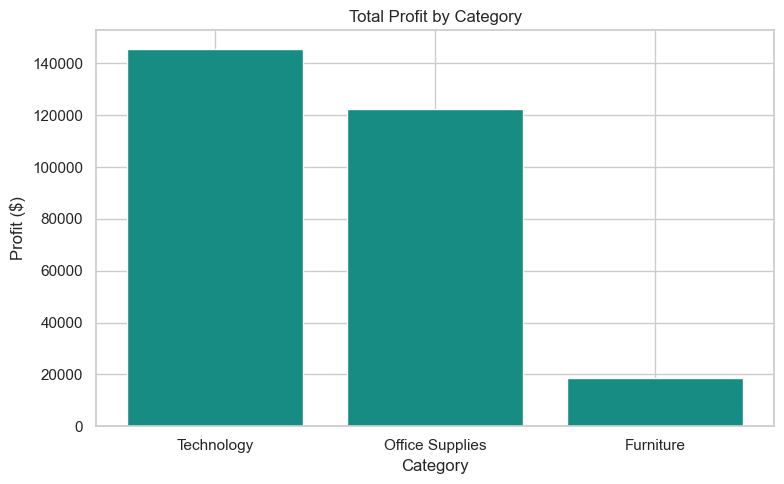

Profit by sub-category (highest to lowest):


,Sub-Category,Profit
6,Copiers,55617.8249
13,Phones,44515.7306
0,Accessories,41936.6357
12,Paper,34053.5693
3,Binders,30221.7633
5,Chairs,26590.1663
14,Storage,21278.8264
1,Appliances,18138.0054
9,Furnishings,13059.1436
7,Envelopes,6964.1767


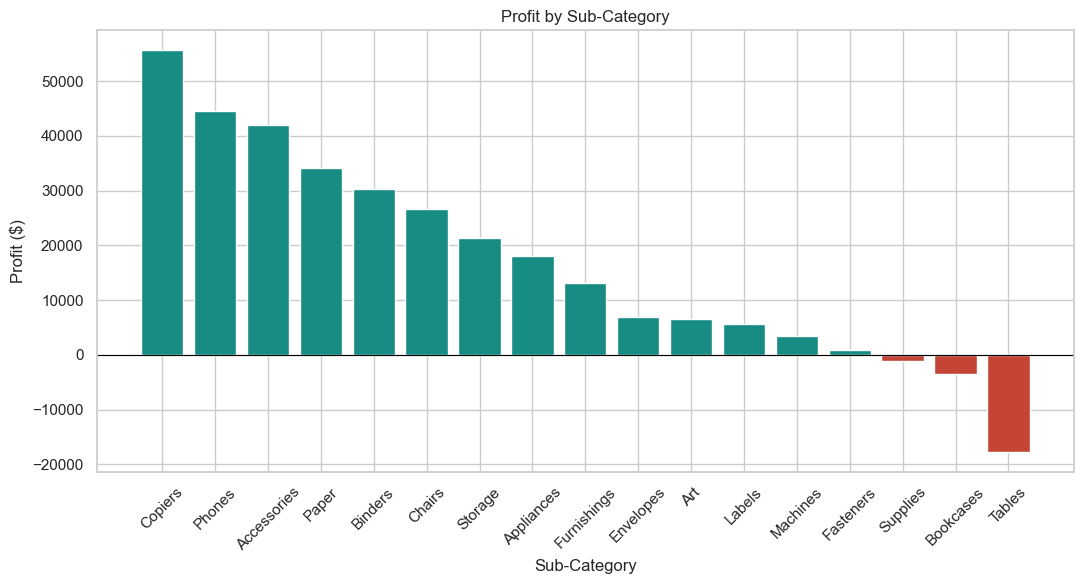

In [14]:
if {"Category", "Sub-Category", "Profit"}.issubset(df.columns):
    category_profit = (
        df.groupby("Category", as_index=False)["Profit"]
        .sum()
        .sort_values("Profit", ascending=False)
    )
    subcategory_profit = (
        df.groupby("Sub-Category", as_index=False)["Profit"]
        .sum()
        .sort_values("Profit", ascending=False)
    )

    print("Total profit by category:")
    display(category_profit)

    fig, ax = plt.subplots(figsize=(8, 5))
    colors = ["#168C83" if value >= 0 else "#C44536" for value in category_profit["Profit"]]
    ax.bar(category_profit["Category"], category_profit["Profit"], color=colors)
    ax.set(title="Total Profit by Category", xlabel="Category", ylabel="Profit ($)")
    plt.tight_layout()
    plt.show()

    print("Profit by sub-category (highest to lowest):")
    display(subcategory_profit)

    fig, ax = plt.subplots(figsize=(11, 6))
    colors = ["#168C83" if value >= 0 else "#C44536" for value in subcategory_profit["Profit"]]
    ax.bar(subcategory_profit["Sub-Category"], subcategory_profit["Profit"], color=colors)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set(title="Profit by Sub-Category", xlabel="Sub-Category", ylabel="Profit ($)")
    ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("Profit analysis unavailable: this CSV has no 'Profit' column.")
    print("Use a Superstore file containing Profit to identify profitable or loss-making categories.")

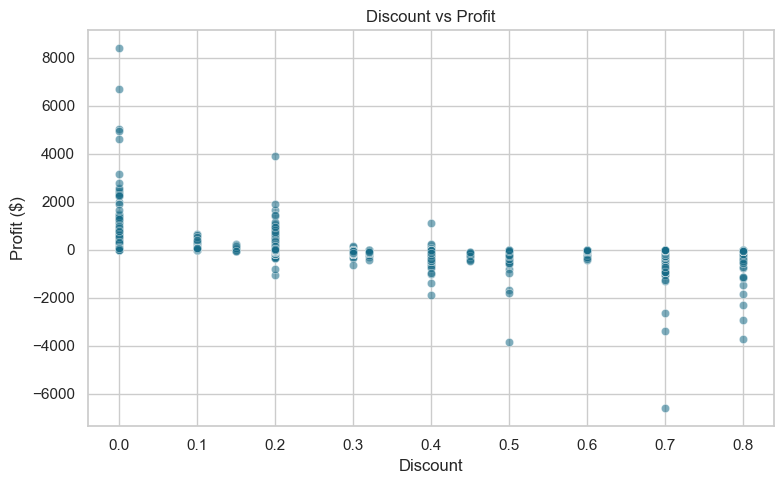

Correlation between Discount and Profit: -0.219


In [15]:
if {"Discount", "Profit"}.issubset(df.columns):
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.scatterplot(data=df, x="Discount", y="Profit", alpha=0.55, color="#176B87", ax=ax)
    ax.set(title="Discount vs Profit", xlabel="Discount", ylabel="Profit ($)")
    plt.tight_layout()
    plt.show()

    discount_profit_corr = df["Discount"].corr(df["Profit"])
    print(f"Correlation between Discount and Profit: {discount_profit_corr:.3f}")
else:
    print("Discount vs profit analysis unavailable: this CSV has no 'Discount' and/or 'Profit' column.")
    print("Use a Superstore file containing both columns to calculate their correlation.")

In [16]:
# CEO takeaway - fixed
# Sales leaders from grouped tables
print(df.groupby('Category')['Sales'].sum())
print("Top Category:", df.groupby('Category')['Sales'].sum().idxmax())
print("Top Region:", df.groupby('Region')['Sales'].sum().idxmax())

# A loss-making sub-category requires Profit data.
if "Profit" in df.columns:
    loss_subcategories = subcategory_profit[subcategory_profit["Profit"] < 0]
    if loss_subcategories.empty:
        print("No sub-categories have negative total profit.")
    else:
        worst_subcategory = loss_subcategories.iloc[-1]
        print(
            f"Largest sub-category loss: {worst_subcategory['Sub-Category']} "
            f"(${worst_subcategory['Profit']:,.2f})"
        )
else:
    print("Loss-making sub-category: unavailable because this CSV has no Profit column.")

Category
Furniture          741999.7953
Office Supplies    719047.0320
Technology         836154.0330
Name: Sales, dtype: float64
Top Category: Technology
Top Region: West
Largest sub-category loss: Tables ($-17,725.48)
